# 02. Mô hình Hồi quy Logistic tự cài đặt (NumPy)

Huấn luyện `LogisticRegressionScratch` bằng Batch Gradient Descent có điều chuẩn L2, khảo sát tốc độ học và đánh giá trên tập kiểm tra.

Tương ứng mục 4.4 và phần đầu Chương 5 của báo cáo.

In [1]:
import os, sys
# Chạy từ thư mục notebooks/: chuyển về thư mục gốc dự án để đường dẫn tương đối hoạt động
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.data import preprocess as pp
from src.models.logistic_regression_scratch import LogisticRegressionScratch
from src.models import evaluate as ev
from src.utils import visualization as viz

data = pp.run()   # đọc, làm sạch, chia 80/20, chuẩn hóa, lưu vào data/processed
print("Số đặc trưng:", data.X_train.shape[1])

Số mẫu gốc: 1599 | giá trị thiếu: 0 | bản ghi trùng: 240
Sau làm sạch: 1359 mẫu | train: 1087 (575 nhãn 1) | test: 272 (144 nhãn 1)
Số đặc trưng: 11


## 1. Huấn luyện với cấu hình chọn trong báo cáo

`lr = 0.5`, `lam = 1` (tương ứng `C = 1` trong scikit-learn), ngưỡng dừng `1e-12`.

In [2]:
model = LogisticRegressionScratch(lr=0.5, n_iter=50000, lam=1.0, tol=1e-12)
model.fit(data.X_train, data.y_train)
print("Số vòng lặp:", len(model.history))
print("Hàm mất mát cuối cùng:", round(model.history[-1], 6))
pd.Series(model.w, index=data.feature_names).sort_values(key=abs, ascending=False).round(4)

Số vòng lặp: 1354
Hàm mất mát cuối cùng: 0.514111


alcohol                 0.9868
total sulfur dioxide   -0.5174
sulphates               0.4769
volatile acidity       -0.4768
chlorides              -0.2168
fixed acidity           0.1956
free sulfur dioxide     0.1831
citric acid            -0.1395
density                -0.0764
pH                     -0.0740
residual sugar          0.0571
dtype: float64

## 2. Khảo sát tốc độ học

,lr,so_vong_lap,loss_cuoi
0,0.05,10933,0.514111
1,0.50,1354,0.514111
2,2.00,428,0.514111


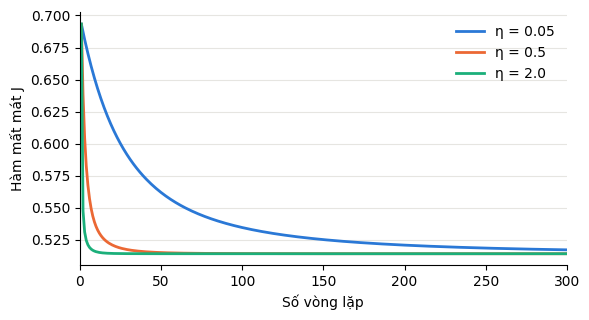

In [3]:
histories, rows = {}, []
for lr in (0.05, 0.5, 2.0):
    m = LogisticRegressionScratch(lr=lr, n_iter=50000, lam=1.0, tol=1e-12).fit(data.X_train, data.y_train)
    histories[f"η = {lr}"] = m.history
    rows.append({"lr": lr, "so_vong_lap": len(m.history), "loss_cuoi": round(m.history[-1], 6)})
display(pd.DataFrame(rows))
fig = viz.plot_loss_curves(histories, max_iter=300)
viz.save(fig, "4_3_loss_curves.png")
plt.show()

Cả ba tốc độ học hội tụ về cùng một giá trị hàm mất mát (hàm lồi), chỉ khác số vòng lặp.

## 3. Đánh giá trên tập kiểm tra

In [4]:
proba = model.predict_proba(data.X_test)
metrics = ev.compute_metrics(data.y_test, proba)
print(f"Mốc accuracy (luôn đoán lớp đông hơn): {ev.majority_baseline(data.y_test):.4f}")
pd.Series(metrics).round(4)

Mốc accuracy (luôn đoán lớp đông hơn): 0.5294


accuracy       0.7353
precision      0.7609
recall         0.7292
f1             0.7447
roc_auc        0.8116
log_loss       0.5241
TN            95.0000
FP            33.0000
FN            39.0000
TP           105.0000
dtype: float64

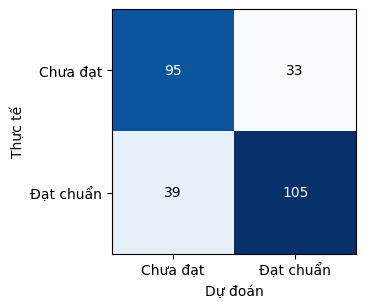

In [5]:
cm = np.array([[metrics["TN"], metrics["FP"]], [metrics["FN"], metrics["TP"]]])
fig = viz.plot_confusion_matrix(cm)
viz.save(fig, "5_confusion_matrix_scratch.png")
plt.show()

## 4. Lưu mô hình

In [6]:
os_path = "saved_models/logistic_scratch.npz"
np.savez(os_path, w=model.w, b=model.b, history=np.array(model.history))
print("Đã lưu:", os_path)

Đã lưu: saved_models/logistic_scratch.npz
